# OOD Monitoring as a SOTIF Safety Measure

**Module 04 · SOTIF (ISO 21448)** · Notebook 3 of 5

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/04_SOTIF_ISO21448/03_ood_monitoring_as_safety_measure.ipynb)

| Level | Time | Prerequisites | Standards |
|---|---|---|---|
| Intermediate | ~60 min | [01 · SOTIF fundamentals](01_sotif_fundamentals.ipynb), [02/03 · OOD detection methods](../02_Failures_and_Robustness/03_out_of_distribution_detection.ipynb) | ISO 21448:2022, ISO/PAS 8800:2024, UN R157 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

- Place an out-of-distribution (OOD) monitor correctly in the ISO 21448 causal chain and activity flow
- Set a monitor threshold **from a safety requirement** instead of an arbitrary percentile
- Convert a false-positive rate into **false alarms per hour** and design a temporal filter
- Treat the TPR/FPR trade-off as a **safety vs availability** decision and document it
- Choose a fallback that fits the **level of automation** (L2 warning, L3 transition demand, L4 minimal risk manoeuvre)
- State the limits: OOD is not the same as hazardous, and the monitor needs its own validation

This notebook does **not** re-derive OOD scoring methods; Mahalanobis, k-NN, MSP, energy scores and their
evaluation are covered in [02/03 · Out-of-distribution detection](../02_Failures_and_Robustness/03_out_of_distribution_detection.ipynb).
Here an OOD score is treated as a given signal, and the question is how to turn it into a **safety measure** that
can be argued in a SOTIF case.

In [1]:
# Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy import stats
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score, roc_curve

rng = np.random.default_rng(42)
OI = {'orange': '#E69F00', 'sky': '#56B4E9', 'green': '#009E73', 'yellow': '#F0E442',
      'blue': '#0072B2', 'vermillion': '#D55E00', 'purple': '#CC79A7', 'grey': '#999999', 'black': '#000000'}
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
print("Setup complete.")

Setup complete.


## 1. Where an OOD monitor sits in ISO 21448

A perception model trained on finite data has **performance insufficiencies** outside the conditions it was trained
and validated for. An OOD monitor estimates at runtime whether the current input resembles that data. In SOTIF terms:

| SOTIF concept | Role of the OOD monitor |
|---|---|
| Functional insufficiency (performance, training-data coverage) | The monitor flags inputs the model is unlikely to handle — a **functional modification** (clause 8) that mitigates the insufficiency |
| Triggering conditions | Logged OOD events are **candidate triggering conditions** for offline analysis (clause 7) |
| Area 3 (unknown, hazardous) | Field OOD logs support **discovery** of unknown scenarios (clauses 11 and 13) |
| Operation phase (clause 13) | Fleet-wide OOD statistics show drift of the operating environment |
| Hazardous behaviour | The monitor itself does nothing safe — only the **fallback** it triggers does |

Two limits must be stated in any safety argument:

- **OOD ≠ hazardous.** Many novel inputs are handled well (Area 4), and many failures happen on in-distribution
  inputs. The monitor reduces, not removes, the residual risk.
- **The monitor has insufficiencies of its own** (missed OOD, false alarms) and needs its own requirements and V&V.
  ISO/PAS 8800:2024 discusses such monitors as safety measures for AI elements (see [Module 06](../06_AI_Safety_ISO_PAS_8800/01_ai_safety_standards.ipynb)).

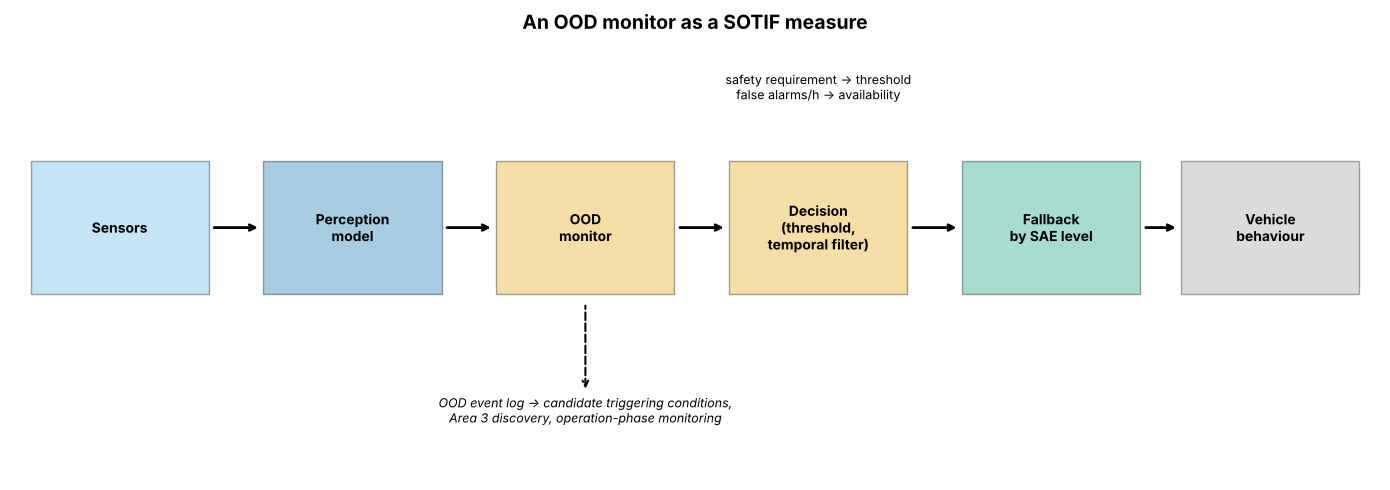

In [2]:
def visualize_monitor_in_chain():
    """OOD monitor as a measure between perception output and vehicle behaviour."""
    fig, ax = plt.subplots(figsize=(14, 5))
    boxes = [('Sensors', 0.08, OI['sky']), ('Perception\nmodel', 0.25, OI['blue']), ('OOD\nmonitor', 0.42, OI['orange']),
             ('Decision\n(threshold,\ntemporal filter)', 0.59, OI['orange']), ('Fallback\nby SAE level', 0.76, OI['green']),
             ('Vehicle\nbehaviour', 0.92, OI['grey'])]
    for label, x, col in boxes:
        ax.add_patch(plt.Rectangle((x - 0.065, 0.42), 0.13, 0.3, facecolor=col, alpha=0.35, edgecolor='black'))
        ax.text(x, 0.57, label, ha='center', va='center', fontsize=10, fontweight='bold')
    for (_, x0, _), (_, x1, _) in zip(boxes[:-1], boxes[1:]):
        ax.annotate('', xy=(x1 - 0.067, 0.57), xytext=(x0 + 0.067, 0.57), arrowprops=dict(arrowstyle='->', lw=2))
    ax.annotate('', xy=(0.42, 0.40), xytext=(0.42, 0.20), arrowprops=dict(arrowstyle='<-', lw=1.5, ls='--'))
    ax.text(0.42, 0.13, 'OOD event log → candidate triggering conditions,\nArea 3 discovery, operation-phase monitoring',
            ha='center', fontsize=9, style='italic')
    ax.text(0.59, 0.86, 'safety requirement → threshold\nfalse alarms/h → availability', ha='center', fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
    ax.set_title('An OOD monitor as a SOTIF measure', fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()

visualize_monitor_in_chain()

## 2. A synthetic perception feature space

> **Illustrative data:** a synthetic 2-D feature embedding, chosen for teaching; it is not derived from a real
> perception model. In-distribution (ID) data stand for frames from the specified ODD; *near-OOD* stands for a
> covariate shift (e.g. snowfall outside the ODD), *far-OOD* for grossly unfamiliar inputs (e.g. a blocked sensor).

Training, validation and test ID data come **from the same distribution** (one random split). This matters: if the
ID test set were drawn from a different distribution than the training set, every ID frame would be flagged as OOD
— a bug present in an earlier version of this notebook.

In [3]:
MU_ID = np.array([0.0, 0.0])
COV_ID = np.array([[1.0, 0.6], [0.6, 1.5]])

X_id = rng.multivariate_normal(MU_ID, COV_ID, size=6000)
X_train, X_val_id, X_test_id = X_id[:2000], X_id[2000:4000], X_id[4000:]           # same distribution, disjoint

def sample_ood(n, rng):
    """Half near-OOD (shifted cluster), half far-OOD (ring at large radius)."""
    near = rng.multivariate_normal([2.8, -2.2], 0.6 * np.eye(2), size=n // 2)
    r = rng.uniform(4.5, 8.0, n - n // 2); a = rng.uniform(0, 2 * np.pi, n - n // 2)
    far = np.c_[r * np.cos(a), r * np.sin(a)]
    return np.vstack([near, far]), np.r_[np.zeros(n // 2), np.ones(n - n // 2)]   # 0 = near, 1 = far

X_val_ood, kind_val = sample_ood(1000, rng)
X_test_ood, kind_test = sample_ood(1000, rng)


class MahalanobisOODDetector:
    """Mahalanobis distance to the training distribution (single Gaussian), vectorised."""

    def fit(self, X):
        self.mean = X.mean(axis=0)
        self.cov = np.cov(X.T) + 1e-6 * np.eye(X.shape[1])
        self.cov_inv = np.linalg.inv(self.cov)
        return self

    def score(self, X):
        d = np.atleast_2d(X) - self.mean
        return np.sqrt(np.einsum('ij,jk,ik->i', d, self.cov_inv, d))


class KNNOODDetector:
    """Mean distance to the k nearest training points; excludes the point itself only when scoring training data."""

    def __init__(self, k=10):
        self.k = k

    def fit(self, X):
        self.nn = NearestNeighbors().fit(X)
        return self

    def score(self, X, exclude_self=False):
        d, _ = self.nn.kneighbors(np.atleast_2d(X), n_neighbors=self.k + int(exclude_self))
        return d[:, int(exclude_self):].mean(axis=1)


maha = MahalanobisOODDetector().fit(X_train)
knn = KNNOODDetector(k=10).fit(X_train)

y_test = np.r_[np.zeros(len(X_test_id)), np.ones(len(X_test_ood))]
for name, det in [('Mahalanobis', maha), ('k-NN (k=10)', knn)]:
    s = np.r_[det.score(X_test_id), det.score(X_test_ood)]
    near = np.r_[det.score(X_test_id), det.score(X_test_ood[kind_test == 0])]
    y_near = np.r_[np.zeros(len(X_test_id)), np.ones((kind_test == 0).sum())]
    print(f"{name:12s}  AUROC all OOD {roc_auc_score(y_test, s):.3f} | near-OOD only {roc_auc_score(y_near, near):.3f}")

Mahalanobis   AUROC all OOD 0.998 | near-OOD only 0.995
k-NN (k=10)   AUROC all OOD 0.996 | near-OOD only 0.993


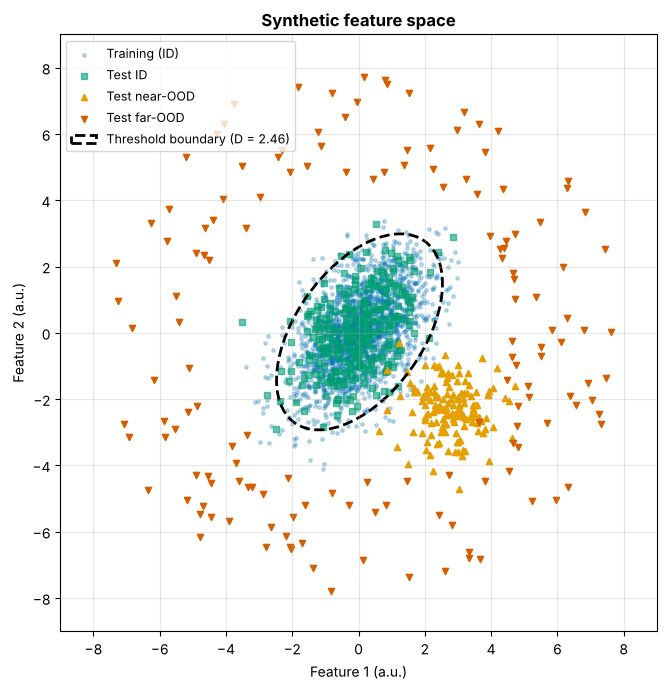

Dashed: the conventional '95th percentile of training scores' threshold — examined critically next.


In [4]:
def plot_feature_space(det, threshold=None):
    fig, ax = plt.subplots(figsize=(7.5, 7))
    ax.scatter(*X_train.T, s=6, color=OI['blue'], alpha=0.25, label='Training (ID)')
    ax.scatter(*X_test_id[:300].T, s=14, color=OI['green'], marker='s', alpha=0.6, label='Test ID')
    ax.scatter(*X_test_ood[kind_test == 0][:150].T, s=20, color=OI['orange'], marker='^', label='Test near-OOD')
    ax.scatter(*X_test_ood[kind_test == 1][:150].T, s=20, color=OI['vermillion'], marker='v', label='Test far-OOD')
    if threshold is not None:
        # Eigen-decomposition of the symmetric covariance: eigh returns real values (eig may return complex ones,
        # which makes np.arctan2 raise a TypeError)
        vals, vecs = np.linalg.eigh(det.cov)
        angle = np.degrees(np.arctan2(vecs[1, -1], vecs[0, -1]))
        width, height = 2 * threshold * np.sqrt(vals[::-1])
        ax.add_patch(Ellipse(det.mean, width, height, angle=angle, fill=False, color=OI['black'], lw=2, ls='--',
                             label=f'Threshold boundary (D = {threshold:.2f})'))
    ax.set_xlim(-9, 9); ax.set_ylim(-9, 9); ax.set_aspect('equal')
    ax.set_xlabel('Feature 1 (a.u.)'); ax.set_ylabel('Feature 2 (a.u.)')
    ax.set_title('Synthetic feature space', fontweight='bold'); ax.legend(loc='upper left', fontsize=9)
    plt.tight_layout(); plt.show()

plot_feature_space(maha, threshold=np.percentile(maha.score(X_train), 95))
print("Dashed: the conventional '95th percentile of training scores' threshold — examined critically next.")

## 3. Setting the threshold from a safety requirement

A threshold such as "95th percentile of the training scores" fixes the **false-positive rate** at about 5 % and
leaves the detection rate to chance. A safety measure is specified the other way round, from what the hazard
analysis needs. An illustrative requirement:

> **R-OOD-1** *The monitor shall flag at least 95 % of frames from the specified OOD validation conditions,
> demonstrated with 95 % confidence.*

Procedure: pick the **highest** threshold whose detection rate on the OOD validation set still has a one-sided
95 % Clopper–Pearson lower bound ≥ 0.95. Then read off what this costs on in-distribution data.

**False alarms per hour.** At a frame rate $f$ (frames/s) a per-frame false-positive rate $\mathrm{FPR}$ gives
$\mathrm{FPR}\cdot f \cdot 3600$ flagged frames per hour — before any temporal filtering.

In [5]:
FPS = 10                      # perception frame rate (frames per second), illustrative
REQ_TPR, REQ_CONF = 0.95, 0.95

def cp_lower(k, n, conf=0.95):
    """One-sided Clopper–Pearson lower confidence bound for a binomial proportion."""
    return 0.0 if k == 0 else stats.beta.ppf(1 - conf, k, n - k + 1)

def threshold_from_requirement(scores_ood, req_tpr=REQ_TPR, conf=REQ_CONF):
    """Highest threshold t such that the CP lower bound of P(score > t | OOD) >= req_tpr."""
    n = len(scores_ood)
    for t in np.sort(scores_ood)[::-1]:                 # descending: from strict to permissive
        k = int((scores_ood > t).sum())
        if cp_lower(k, n, conf) >= req_tpr:
            return t, k / n, cp_lower(k, n, conf)
    raise ValueError("requirement cannot be met with this validation set")

s_val_id, s_val_ood = maha.score(X_val_id), maha.score(X_val_ood)
t_req, tpr_val, tpr_lb = threshold_from_requirement(s_val_ood)
fpr_req = (s_val_id > t_req).mean()

t_p95 = np.percentile(maha.score(X_train), 95)
rows = []
for name, t in [('95th percentile of training scores', t_p95), ('From requirement R-OOD-1', t_req)]:
    fpr = (s_val_id > t).mean(); tpr = (s_val_ood > t).mean()
    rows.append({'Threshold rule': name, 'Threshold D': t, 'TPR (OOD val)': tpr,
                 'TPR 95% lower bound': cp_lower(int((s_val_ood > t).sum()), len(s_val_ood)),
                 'FPR (ID val)': fpr, 'Flagged ID frames per hour': fpr * FPS * 3600})
thr_table = pd.DataFrame(rows)
display(thr_table.round(4))

near_tpr = (maha.score(X_val_ood[kind_val == 0]) > t_req).mean()
far_tpr = (maha.score(X_val_ood[kind_val == 1]) > t_req).mean()
print(f"Text summary: meeting R-OOD-1 requires D > {t_req:.2f}; it flags {fpr_req:.1%} of ID frames, i.e. "
      f"{fpr_req*FPS*3600:,.0f} flagged frames per hour at {FPS} fps before filtering. "
      f"Detection rate: near-OOD {near_tpr:.1%}, far-OOD {far_tpr:.1%}.")

,Threshold rule,Threshold D,TPR (OOD val),TPR 95% lower bound,FPR (ID val),Flagged ID frames per hour
0,95th percentile of training scores,2.4586,0.993,0.9869,0.0520,1872.0
1,From requirement R-OOD-1,3.2057,0.962,0.9505,0.0065,234.0


Text summary: meeting R-OOD-1 requires D > 3.21; it flags 0.7% of ID frames, i.e. 234 flagged frames per hour at 10 fps before filtering. Detection rate: near-OOD 92.4%, far-OOD 100.0%.


Hundreds or thousands of flagged frames per hour are useless as a direct trigger for a fallback. Two levers follow:
**temporal filtering** (Section 4) and a **better separating signal** (features, sensors) — or a narrower ODD.

## 4. Temporal filtering: k-out-of-n

An alarm is raised when at least $k$ of the last $n$ frames are flagged. For *independent* frames with flag
probability $p$, the probability that a given window alarms is $P(\mathrm{Bin}(n,p) \ge k)$, which falls steeply.
Real frames are **correlated** — a patch of glare lasts for many frames — so filtering helps less. Below, an hour of
ID driving is simulated both ways; the correlated sequence has the same marginal distribution (AR(1) process,
correlation 0.95 between consecutive frames). We count alarm **onsets** (rising edges) per hour and measure the
detection latency when an OOD episode starts.

In [6]:
L_ID = np.linalg.cholesky(COV_ID)

def id_sequence(n_frames, rho, rng):
    """ID features with lag-1 correlation rho and the ID marginal distribution."""
    z = np.empty((n_frames, 2)); z[0] = rng.standard_normal(2)
    e = rng.standard_normal((n_frames, 2))
    for t in range(1, n_frames):
        z[t] = rho * z[t - 1] + np.sqrt(1 - rho ** 2) * e[t]
    return MU_ID + z @ L_ID.T

def alarms(flags, k, n):
    win = np.convolve(flags.astype(int), np.ones(n, dtype=int), mode='full')[:len(flags)]
    return win >= k

def onsets_per_hour(flags, k, n, fps=FPS):
    a = alarms(flags, k, n)
    onsets = np.sum(a[1:] & ~a[:-1]) + int(a[0])
    return onsets / (len(flags) / fps / 3600)

def latency_s(det, threshold, k, n, n_episodes=500, episode_len=40, rng=rng):
    """Seconds from OOD-episode start to the first alarm (np.inf if not within the episode)."""
    lat = []
    for _ in range(n_episodes):
        X, _ = sample_ood(episode_len, rng)
        X = X[rng.permutation(episode_len)]
        a = alarms(det.score(X) > threshold, k, n)
        lat.append((np.argmax(a) + 1) / FPS if a.any() else np.inf)
    return np.array(lat)

HOURS = 5
flags_indep = maha.score(MU_ID + rng.standard_normal((HOURS * 3600 * FPS, 2)) @ L_ID.T) > t_req
flags_corr = maha.score(id_sequence(HOURS * 3600 * FPS, 0.95, rng)) > t_req

rows = []
for k, n in [(1, 1), (2, 3), (3, 5), (5, 10), (8, 10)]:
    lat = latency_s(maha, t_req, k, n)
    rows.append({'filter k-of-n': f'{k}-of-{n}',
                 'false alarms/h (independent frames)': onsets_per_hour(flags_indep, k, n),
                 'false alarms/h (correlated frames)': onsets_per_hour(flags_corr, k, n),
                 'median latency (s)': np.median(lat),
                 'P(alarm within 1 s)': np.mean(lat <= 1.0)})
filt = pd.DataFrame(rows)
display(filt.round(3))
best = filt.iloc[filt['false alarms/h (correlated frames)'].idxmin()]
print(f"Text summary: with the requirement-based threshold, the {best['filter k-of-n']} filter gives the fewest "
      f"false alarms on correlated data ({best['false alarms/h (correlated frames)']:.1f} per hour), at a median "
      f"latency of {best['median latency (s)']:.1f} s. With independent frames the same filter would give "
      f"{best['false alarms/h (independent frames)']:.1f} false alarms per hour — correlation between frames makes "
      f"filtering much less effective.")

,filter k-of-n,false alarms/h (independent frames),false alarms/h (correlated frames),median latency (s),P(alarm within 1 s)
0,1-of-1,216.4,81.2,0.1,1.000
1,2-of-3,1.8,42.0,0.2,1.000
2,3-of-5,0.4,26.2,0.3,1.000
3,5-of-10,0.0,16.4,0.5,1.000
4,8-of-10,0.0,6.4,0.8,0.998


Text summary: with the requirement-based threshold, the 8-of-10 filter gives the fewest false alarms on correlated data (6.4 per hour), at a median latency of 0.8 s. With independent frames the same filter would give 0.0 false alarms per hour — correlation between frames makes filtering much less effective.


## 5. Safety vs availability: the trade-off as a decision

Every threshold is a point on a curve: higher detection of OOD inputs (safety) costs more false alarms
(availability, and — for an automated vehicle — possibly new hazards from unnecessary manoeuvres). The plot shows,
for the 8-of-10 filter on correlated ID data, the frame-level detection rate against false alarms per hour.

> **Illustrative targets:** detection rate ≥ 95 % (R-OOD-1) and at most 0.1 false alarms per hour (one per ten
> hours) are teaching values. Real targets come from the hazard analysis (cost of a missed OOD episode) and from the
> hazards and customer impact of the fallback.

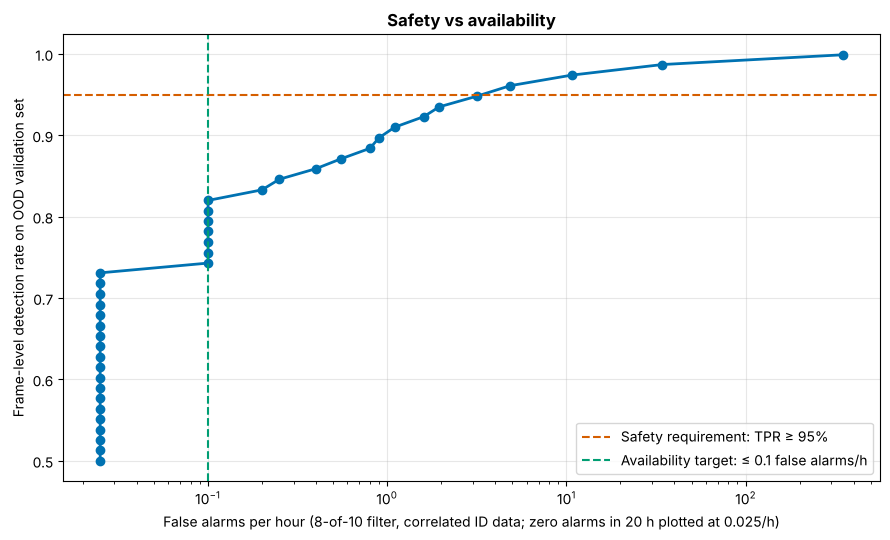

Text summary: no threshold meets both targets — at TPR ≥ 95% the best is 4.85 false alarms/h. Options to record in the SOTIF analysis: better features or sensors, a narrower ODD, a less disruptive fallback, or a justified change of target.


In [7]:
K_F, N_F = 8, 10
AVAIL_TARGET = 0.1            # false alarms per hour (illustrative)
HOURS_T = 20                  # longer simulation for resolving low false-alarm rates
s_corr = maha.score(id_sequence(HOURS_T * 3600 * FPS, 0.95, rng))

thresholds = np.quantile(s_val_ood, np.linspace(0.0, 0.5, 40))
curve = pd.DataFrame({'threshold': thresholds,
                      'TPR': [(s_val_ood > t).mean() for t in thresholds],
                      'false_alarms_per_h': [onsets_per_hour(s_corr > t, K_F, N_F) for t in thresholds]})
feasible = curve[(curve['TPR'] >= REQ_TPR) & (curve['false_alarms_per_h'] <= AVAIL_TARGET)]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(np.maximum(curve['false_alarms_per_h'], 1 / HOURS_T / 2), curve['TPR'], 'o-', color=OI['blue'], lw=2)
ax.axhline(REQ_TPR, color=OI['vermillion'], ls='--', label=f'Safety requirement: TPR ≥ {REQ_TPR:.0%}')
ax.axvline(AVAIL_TARGET, color=OI['green'], ls='--', label=f'Availability target: ≤ {AVAIL_TARGET} false alarms/h')
ax.set_xscale('log')
ax.set_xlabel(f'False alarms per hour ({K_F}-of-{N_F} filter, correlated ID data; zero alarms in 20 h plotted at 0.025/h)')
ax.set_ylabel('Frame-level detection rate on OOD validation set')
ax.set_title('Safety vs availability', fontweight='bold'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

if len(feasible):
    print(f"Text summary: {len(feasible)} of {len(curve)} thresholds satisfy both targets "
          f"(e.g. D = {feasible['threshold'].iloc[-1]:.2f}).")
else:
    at_req = curve[curve['TPR'] >= REQ_TPR]['false_alarms_per_h'].min()
    print(f"Text summary: no threshold meets both targets — at TPR ≥ {REQ_TPR:.0%} the best is "
          f"{at_req:.2f} false alarms/h. Options to record in the SOTIF analysis: better features or sensors, "
          f"a narrower ODD, a less disruptive fallback, or a justified change of target.")

## 6. Fallback by level of automation

What an alarm should *do* depends on who is the fallback (SAE J3016:2021):

| Level | Who is the fallback | Fitting reaction to a sustained OOD alarm |
|---|---|---|
| **L2** (driver assistance) | The driver, who supervises continuously | Warn; request hands-on / eyes-on; degrade or switch off the function with a clear message |
| **L3** (conditional automation) | The fallback-ready user, after a **transition demand** | Issue a transition demand; if the driver does not take over, perform a minimal risk manoeuvre. For ALKS, UN Regulation No. 157 allows the MRM to start at the earliest 10 s after the transition demand begins (earlier for severe failures) |
| **L4** (high automation) | The ADS itself — no takeover is expected | Degrade (reduce speed, increase headway), then perform a **minimal risk manoeuvre** to reach a minimal risk condition |

A false alarm is not free: an unnecessary minimal risk manoeuvre on a motorway is itself a hazardous behaviour and
belongs in the hazard analysis.

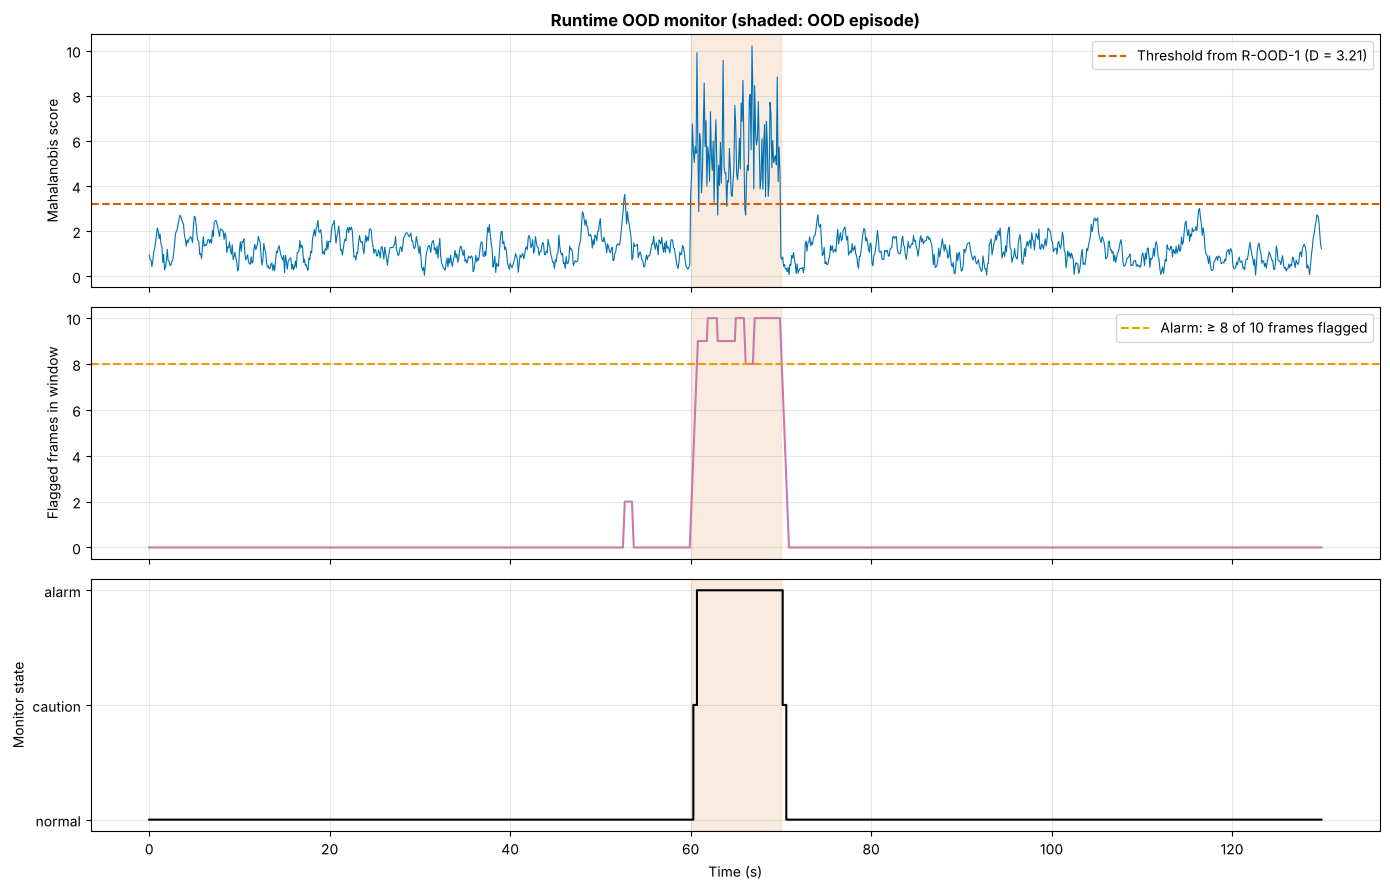

Text summary: false alarm onsets during the 120 s of normal driving: 0; OOD episode detected after 0.8 s.
  L2 reactions during the OOD episode: Hands-on request; function degrades with message (93 frames); Driver warning (4 frames); Continue (3 frames)
  L3 reactions during the OOD episode: Transition demand; MRM if no takeover (93 frames); Increase headway, prepare (4 frames); Continue (3 frames)
  L4 reactions during the OOD episode: Minimal risk manoeuvre (93 frames); Reduce speed, increase headway (4 frames); Continue (3 frames)


In [8]:
def fallback_action(level, state):
    """Reaction to the monitor state ('normal', 'caution', 'alarm') for SAE level 2, 3 or 4."""
    if state == 'normal':
        return 'Continue'
    if level == 2:
        return 'Driver warning' if state == 'caution' else 'Hands-on request; function degrades with message'
    if level == 3:
        return 'Increase headway, prepare' if state == 'caution' else 'Transition demand; MRM if no takeover'
    if level == 4:
        return 'Reduce speed, increase headway' if state == 'caution' else 'Minimal risk manoeuvre'
    raise ValueError("level must be 2, 3 or 4")


class RuntimeOODMonitor:
    """Requirement-based threshold + k-of-n temporal filter + level-dependent fallback."""

    def __init__(self, detector, threshold, k, n, level, caution_fraction=0.4):
        self.detector, self.threshold, self.k, self.n, self.level = detector, threshold, k, n, level
        self.caution_fraction = caution_fraction
        self.history = []

    def process_frame(self, features):
        score = float(self.detector.score(features)[0])
        self.history = (self.history + [score > self.threshold])[-self.n:]
        flagged = sum(self.history)
        state = 'alarm' if flagged >= self.k else ('caution' if flagged >= self.caution_fraction * self.n else 'normal')
        return {'score': score, 'flagged_in_window': flagged, 'state': state,
                'action': fallback_action(self.level, state)}

# Driving sequence: 60 s normal (correlated ID) → 10 s OOD episode → 60 s normal
seq_normal1 = id_sequence(600, 0.95, rng)
seq_ood, _ = sample_ood(100, rng)
seq_normal2 = id_sequence(600, 0.95, rng)
sequence = np.vstack([seq_normal1, seq_ood[rng.permutation(100)], seq_normal2])
ood_mask = np.r_[np.zeros(600, bool), np.ones(100, bool), np.zeros(600, bool)]

results = {}
for level in (2, 3, 4):
    mon = RuntimeOODMonitor(maha, t_req, K_F, N_F, level)
    results[level] = pd.DataFrame([mon.process_frame(x) for x in sequence])
res = results[4]
t_axis = np.arange(len(sequence)) / FPS

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
axes[0].plot(t_axis, res['score'], color=OI['blue'], lw=0.8)
axes[0].axhline(t_req, color=OI['vermillion'], ls='--', label=f'Threshold from R-OOD-1 (D = {t_req:.2f})')
axes[0].set_ylabel('Mahalanobis score'); axes[0].legend(loc='upper right')
axes[1].plot(t_axis, res['flagged_in_window'], color=OI['purple'], lw=1.5)
axes[1].axhline(K_F, color=OI['orange'], ls='--', label=f'Alarm: ≥ {K_F} of {N_F} frames flagged')
axes[1].set_ylabel('Flagged frames in window'); axes[1].legend(loc='upper right')
state_code = res['state'].map({'normal': 0, 'caution': 1, 'alarm': 2})
axes[2].step(t_axis, state_code, where='post', color=OI['black'])
axes[2].set_yticks([0, 1, 2]); axes[2].set_yticklabels(['normal', 'caution', 'alarm'])
axes[2].set_xlabel('Time (s)'); axes[2].set_ylabel('Monitor state')
for ax in axes:
    ax.axvspan(60, 70, color=OI['vermillion'], alpha=0.12)
axes[0].set_title('Runtime OOD monitor (shaded: OOD episode)', fontweight='bold')
plt.tight_layout(); plt.show()

alarm = (res['state'] == 'alarm').values
false_alarm_onsets = np.sum(alarm[1:] & ~alarm[:-1] & ~ood_mask[1:])
first = np.argmax(alarm & ood_mask) if (alarm & ood_mask).any() else None
print("Text summary:",
      f"false alarm onsets during the 120 s of normal driving: {false_alarm_onsets};",
      f"OOD episode detected after {(first - 600 + 1) / FPS:.1f} s." if first is not None else "OOD episode not detected.")
for level in (2, 3, 4):
    acts = results[level].loc[ood_mask, 'action'].value_counts()
    print(f"  L{level} reactions during the OOD episode: " + "; ".join(f"{a} ({c} frames)" for a, c in acts.items()))

## 7. What goes into the SOTIF argument

- **Requirement and rationale:** which OOD conditions the monitor must detect, with which rate and latency, derived
  from the hazard analysis.
- **Evidence:** detection rate with a confidence bound on a validation set that represents the specified OOD
  conditions; false-alarm rate per hour on representative, *temporally correlated* ID data.
- **Fallback:** appropriate to the level of automation; hazards of the fallback analysed.
- **Limitations:** OOD inputs the monitor does not separate (here, part of the near-OOD cluster), and ID failures it
  cannot see — these remain residual risk to be bounded by validation (clauses 10–11).
- **Operation phase:** OOD events are logged and analysed; confirmed new triggering conditions update the analysis.

Uncertainty estimates of the perception model itself can serve a similar purpose; see the author's work on
uncertainty evaluation for identifying performance insufficiencies (Patel & Jung, 2026) and
[Module 06](../06_AI_Safety_ISO_PAS_8800/02_uncertainty_types.ipynb).

## 8. Exercise

1. Implement `LOFOODDetector` with `sklearn.neighbors.LocalOutlierFactor(novelty=True)`; score = `-score_samples(X)`.
2. Set its threshold with `threshold_from_requirement` and compute flagged ID frames per hour.
3. Compare its false alarms per hour (8-of-10 filter, correlated data) with the Mahalanobis monitor. Which would you
   choose, and what would you write in the SOTIF analysis about the remaining near-OOD misses?

In [9]:
# Exercise starter — runs as is; replace the NotImplementedError lines
from sklearn.neighbors import LocalOutlierFactor

class LOFOODDetector:
    def fit(self, X):
        raise NotImplementedError("fit a LocalOutlierFactor(n_neighbors=20, novelty=True) on X")

    def score(self, X):
        raise NotImplementedError("return -self.lof.score_samples(np.atleast_2d(X))")

try:
    lof = LOFOODDetector().fit(X_train)
    t_lof, tpr_lof, _ = threshold_from_requirement(lof.score(X_val_ood))
    fpr_lof = (lof.score(X_val_id) > t_lof).mean()
    print(f"LOF: threshold {t_lof:.3f}, flagged ID frames per hour {fpr_lof * FPS * 3600:,.0f}")
except NotImplementedError as e:
    print("Exercise not yet implemented:", e)

Exercise not yet implemented: fit a LocalOutlierFactor(n_neighbors=20, novelty=True) on X


## Key takeaways

- An OOD monitor is a **functional modification** against performance insufficiencies, and its logs support
  discovery of triggering conditions and Area 3 scenarios. It is not a detector of hazardous scenarios.
- Derive the threshold from a **safety requirement** with a confidence bound; then compute the cost in
  **false alarms per hour** — percentiles of training scores fix the wrong quantity.
- Temporal filtering trades latency for availability, and is less effective on correlated real frames than on
  independent ones.
- When both safety and availability targets cannot be met, the gap is a **documented design decision**: better signal,
  narrower ODD or different fallback.
- The fallback depends on the level of automation: warning (L2), transition demand then MRM (L3), MRM (L4).

## Self-assessment

1. Why is "flags OOD inputs" not the same as "detects unknown hazardous scenarios"?
2. A monitor has a per-frame FPR of 1 % at 20 fps. How many frames per hour are flagged on ID data?
3. Why should the threshold be set from the OOD detection requirement rather than from the 95th percentile of
   training scores?
4. Why does temporal filtering work worse on real driving data than on independent samples?
5. What should an L4 vehicle do on a sustained OOD alarm, and why is "request driver takeover" wrong for it?

<details>
<summary>Answers</summary>

1. OOD measures novelty relative to training data. Novel inputs can be handled safely (Area 4), and hazardous
   behaviour can occur on in-distribution inputs; the monitor covers neither case.
2. 0.01 × 20 × 3600 = 720 flagged frames per hour.
3. The safety argument needs a guaranteed detection rate for specified OOD conditions; a training-score percentile
   fixes only the false-positive rate and leaves the detection rate unspecified.
4. Consecutive frames are correlated, so ID frames that exceed the threshold come in runs; a k-of-n window is then
   often filled by a single run.
5. Degrade and perform a minimal risk manoeuvre. At Level 4 no user is expected to take over; the ADS is its own fallback.
</details>

## References

- ISO 21448:2022 *Road vehicles — Safety of the intended functionality*.
- ISO/PAS 8800:2024 *Road vehicles — Safety and artificial intelligence*. https://www.iso.org/standard/83303.html
- SAE J3016 (2021) *Taxonomy and Definitions for Terms Related to Driving Automation Systems for On-Road Motor Vehicles*.
- UN Regulation No. 157 — Automated Lane Keeping Systems (ALKS); EU publication: https://eur-lex.europa.eu/eli/reg/2021/389/oj
- Henriksson, J., Ursing, S., Erdogan, M., Warg, F., Thorsén, A., Jaxing, J., Örsmark, O., Örtenberg Toftås, M. (2023). Out-of-Distribution Detection as Support for Autonomous Driving Safety Lifecycle. *REFSQ 2023*, LNCS 13975, 233–242. https://doi.org/10.1007/978-3-031-29786-1_16
- Lee, K., Lee, K., Lee, H., Shin, J. (2018). A Simple Unified Framework for Detecting Out-of-Distribution Samples and Adversarial Attacks. *NeurIPS 2018*. arXiv:1807.03888
- Sun, Y., Ming, Y., Zhu, X., Li, Y. (2022). Out-of-Distribution Detection with Deep Nearest Neighbors. *ICML 2022*. arXiv:2204.06507
- Patel, M., Jung, R. (2026). Uncertainty Evaluation to Support Safety of the Intended Functionality Analysis for Identifying Performance Insufficiencies in ML-Based LiDAR Object Detection. *VEHITS 2026*, 154–167. https://doi.org/10.5220/0014967200004030
- Patel, M., Jung, R. (2026). Uncertainty Representation in a SOTIF-Related Use Case with Dempster-Shafer Theory for LiDAR Sensor-Based Object Detection. *CCIS*, Springer, 178–193. https://doi.org/10.1007/978-3-032-23187-1_10

## Further practice

For exercises on diagnosis methods and safety envelopes, see the author's companion repository
*AI Perception Safety Workshop* (external): https://github.com/milinpatel07/AI-Perception-Safety-Workshop

---
**Navigation:** ← [prev: Triggering conditions and scenarios](02_triggering_conditions_and_scenarios.ipynb) · [Module index](README.md) · [next: Simulation-based validation](04_simulation_based_validation.ipynb) →